In [3]:
%cd /home/sagemaker-user/18-794_project

/home/sagemaker-user/18-794_project


In [12]:
from pathlib import Path
import json

import pandas as pd
import torch

from RGB.train_RGB_classifier import train_classifier
from RGB.fine_tune_RGB import fine_tune_rgb

In [7]:
project = Path.cwd()

print("Project:", project)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Unavailable")
print("Data:", (project / "data/Penn_Action/frames/0001/000001.jpg").exists())
print("Weights:", (project / "something-v1_resnet50_16frames.pth.tar").exists())

Project: /home/sagemaker-user/18-794_project
GPU: NVIDIA A10G
Data: True
Weights: True


# Train Classifier with frozen backbone

In [8]:
classifier_config = {
    "experiment_name": "classifier_experiment_1",
    "epochs": 8,
    "batch_size": 4,
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,
    "workers": 2,
    "seed": 666,
}

In [10]:
classifier_best = train_classifier(**classifier_config)

Epoch 1/8 | train loss 2.0446 | val loss 1.6121 | val accuracy 50.72% | best 50.72%
Epoch 2/8 | train loss 1.4654 | val loss 1.3332 | val accuracy 58.88% | best 58.88%
Epoch 3/8 | train loss 1.2525 | val loss 1.2247 | val accuracy 62.89% | best 62.89%
Epoch 4/8 | train loss 1.1180 | val loss 1.1314 | val accuracy 63.72% | best 63.72%
Epoch 5/8 | train loss 1.0467 | val loss 1.1326 | val accuracy 64.32% | best 64.32%
Epoch 6/8 | train loss 1.0111 | val loss 1.0406 | val accuracy 67.65% | best 67.65%
Epoch 7/8 | train loss 0.9277 | val loss 1.0113 | val accuracy 68.48% | best 68.48%
Epoch 8/8 | train loss 0.8974 | val loss 1.0343 | val accuracy 66.67% | best 68.48%


# Fine-tune the entire network

In [13]:
finetune_config = {
    "experiment_name": "finetune_experiment_1",
    "classifier_checkpoint": classifier_best,
    "epochs": 12,
    "batch_size": 4,
    "backbone_lr": 1e-5,
    "classifier_lr": 1e-4,
    "weight_decay": 1e-4,
    "workers": 2,
    "seed": 666,
}

In [14]:
finetune_best = fine_tune_rgb(**finetune_config)

Epoch 1/12 | train loss 0.8352 | val loss 0.5973 | val accuracy 82.31% | best 82.31%
Epoch 2/12 | train loss 0.4654 | val loss 0.4238 | val accuracy 87.68% | best 87.68%
Epoch 3/12 | train loss 0.2976 | val loss 0.3735 | val accuracy 89.27% | best 89.27%
Epoch 4/12 | train loss 0.2332 | val loss 0.3269 | val accuracy 89.87% | best 89.87%
Epoch 5/12 | train loss 0.1764 | val loss 0.2862 | val accuracy 91.16% | best 91.16%
Epoch 6/12 | train loss 0.1625 | val loss 0.2902 | val accuracy 91.23% | best 91.23%
Epoch 7/12 | train loss 0.1162 | val loss 0.2435 | val accuracy 92.52% | best 92.52%
Epoch 8/12 | train loss 0.1175 | val loss 0.2421 | val accuracy 93.42% | best 93.42%
Epoch 9/12 | train loss 0.0750 | val loss 0.2227 | val accuracy 93.50% | best 93.50%
Epoch 10/12 | train loss 0.0710 | val loss 0.2010 | val accuracy 93.20% | best 93.50%
Epoch 11/12 | train loss 0.0514 | val loss 0.2202 | val accuracy 92.89% | best 93.50%
Epoch 12/12 | train loss 0.0623 | val loss 0.2288 | val accurac

# Training and Validation Loss

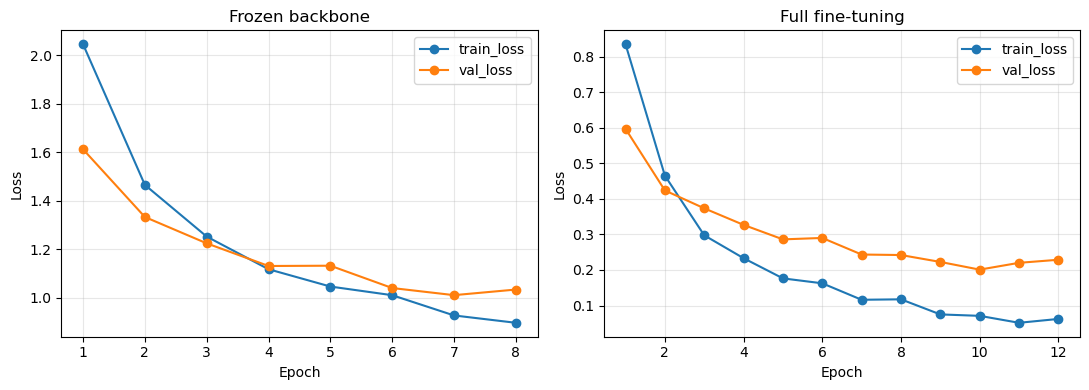

In [20]:
import matplotlib.pyplot as plt
from RGB.train_RGB_classifier import ROOT

classifier_history = pd.DataFrame(json.loads((classifier_best.parent / "history.json").read_text()))
finetune_history = pd.DataFrame(json.loads((finetune_best.parent / "history.json").read_text()))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for i, (history, title) in enumerate([(classifier_history, "Frozen backbone"), (finetune_history, "Full fine-tuning")]):
    history.plot(x="epoch", y=["train_loss", "val_loss"], marker="o", ax=axes[i])
    axes[i].set_title(title)
    axes[i].set_xlabel("Epoch")
    axes[i].set_ylabel("Loss")
    axes[i].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(ROOT / "runs/training_validation_loss.png", dpi=300)
plt.show()

# Test Set Evaluation

In [15]:
import matplotlib.pyplot as plt
from RGB.RGB_model import RGBModel
from RGB.train_RGB_classifier import ROOT, make_loader, validate

classifier_best = ROOT / "runs/rgb_classifier/classifier_experiment_1/best.pt"
finetune_best = ROOT / "runs/rgb_finetune/finetune_experiment_1/best.pt"

In [16]:
def test_model(checkpoint):
    device = torch.device("cuda")
    model = RGBModel()
    model.load_state_dict(torch.load(checkpoint, map_location="cpu", weights_only=True)["model"])
    model.to(device)

    result = validate(model, make_loader("test", 4, 2, device), device)
    result["test_loss"] = result.pop("val_loss")
    (checkpoint.parent / "test_metrics.json").write_text(json.dumps(result, indent=2))
    return result


print("Testing classifier model", flush=True)
classifier_test = test_model(classifier_best)

print("Testing fine-tuned model", flush=True)
finetune_test = test_model(finetune_best)

Testing classifier model
Testing fine-tuned model


##  Test Accuracy Across Observation Ratios

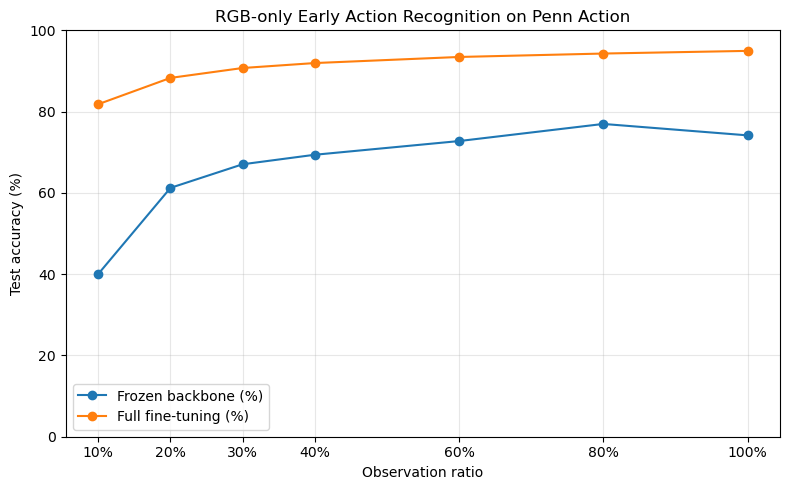

In [18]:
plot_data = test_table.drop(index="Mean").copy()
plot_data.index = [float(ratio.strip("%")) / 100 for ratio in plot_data.index]

ax = plot_data.plot(marker="o", figsize=(8, 5))
ax.set_xticks(plot_data.index, [f"{ratio:.0%}" for ratio in plot_data.index])
ax.set_xlabel("Observation ratio")
ax.set_ylabel("Test accuracy (%)")
ax.set_ylim(0, 100)
ax.set_title("RGB-only Early Action Recognition on Penn Action")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(ROOT / "runs/test_accuracy.png", dpi=300)
plt.show()

test_table.to_csv(ROOT / "runs/test_accuracy_table.csv")

## Test Set Results by Observation Ratio of the video

In [17]:
print(f"Frozen backbone test loss: {classifier_test['test_loss']:.4f}")
print(f"Full fine-tuning test loss: {finetune_test['test_loss']:.4f}")

test_table = pd.DataFrame({"Frozen backbone (%)": classifier_test["accuracy_by_ratio"], "Full fine-tuning (%)": finetune_test["accuracy_by_ratio"]}).astype(float) * 100

test_table.index = test_table.index.astype(float)
test_table = test_table.sort_index()
test_table.index = [f"{ratio:.0%}" for ratio in test_table.index]
test_table.loc["Mean"] = [classifier_test["mean_accuracy"] * 100, finetune_test["mean_accuracy"] * 100]

display(test_table.round(2))

Frozen backbone test loss: 1.0652
Full fine-tuning test loss: 0.3255


,Frozen backbone (%),Full fine-tuning (%)
10%,40.07,81.84
20%,61.24,88.30
30%,67.04,90.73
40%,69.38,91.95
60%,72.75,93.45
80%,76.97,94.29
100%,74.16,94.94
Mean,65.94,90.78
